# Variational Autoencoder (VAE) on a small image dataset

This notebook trains a convolutional VAE on a small custom image dataset (about 200 images in 2 class folders),
then reconstructs images and generates new ones by sampling from the latent space.

**Steps:** setup → load data → build model → train → reconstructions → generate new images

## 1. Setup and settings

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- Settings (change these) ----
DATA_DIR   = "data"      # folder that contains sub-folders of images (e.g. data/1, data/2)
IMG_SIZE   = 64          # images are resized to IMG_SIZE x IMG_SIZE (must be divisible by 8)
BATCH_SIZE = 16
LATENT_DIM = 16
EPOCHS     = 200
LEARNING_RATE = 1e-3
BETA       = 1.0         # weight of the KL term (beta-VAE); lower = sharper images
SEED       = 42

keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


**Running on Colab with Google Drive:** run the cell below and set `DATA_DIR` to your folder, for example
`/content/drive/MyDrive/data_2`. On a local machine, skip it.

In [2]:
# Colab only
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/data_2'

Mounted at /content/drive


## 2. Load the data

Images are resized and scaled to [0, 1]. 20% of the images are kept for validation.
Augmentation (flip, small rotation and zoom) is applied to the training set only.

Found 200 files.
Using 160 files for training.
Found 200 files.
Using 40 files for validation.


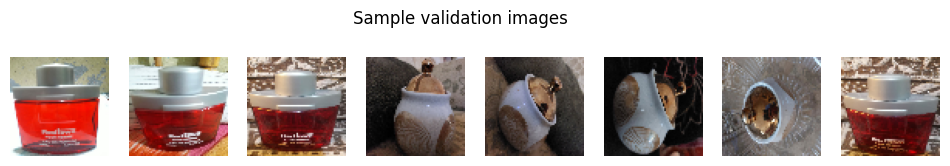

In [3]:
def load_split(subset):
    ds = keras.utils.image_dataset_from_directory(
        DATA_DIR,
        labels="inferred", label_mode=None,   # images only, no labels needed for a VAE
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        validation_split=0.2, subset=subset, seed=SEED,
        shuffle=True,
    )
    return ds.map(lambda x: x / 255.0)

train_raw = load_split("training")
val_ds    = load_split("validation").cache().prefetch(tf.data.AUTOTUNE)

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])
train_ds = (train_raw
            .map(lambda x: tf.clip_by_value(augment(x, training=True), 0.0, 1.0),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))

sample_batch = next(iter(val_ds))
plt.figure(figsize=(12, 2))
for i in range(min(8, len(sample_batch))):
    plt.subplot(1, 8, i + 1)
    plt.imshow(sample_batch[i]); plt.axis("off")
plt.suptitle("Sample validation images"); plt.show()

## 3. Build the model

**Encoder:** 3 strided conv layers → dense → `z_mean` and `z_log_var`.
**Sampling (reparameterization trick):** `z = z_mean + exp(0.5 * z_log_var) * epsilon`, with `epsilon ~ N(0, 1)`.
**Decoder:** mirror of the encoder using transposed convolutions, sigmoid output.
**Loss:** reconstruction error (sum over pixels) + `BETA` × KL divergence.

In [4]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

# Encoder
enc_in = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_in)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
z_mean    = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])
encoder = keras.Model(enc_in, [z_mean, z_log_var, z], name="encoder")

# Decoder
s = IMG_SIZE // 8
dec_in = keras.Input(shape=(LATENT_DIM,))
x = layers.Dense(256, activation="relu")(dec_in)
x = layers.Dense(s * s * 128, activation="relu")(x)
x = layers.Reshape((s, s, 128))(x)
x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
dec_out = layers.Conv2DTranspose(3, 3, strides=2, padding="same", activation="sigmoid")(x)
decoder = keras.Model(dec_in, dec_out, name="decoder")

encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │     18,496 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 8, 128) │     73,856 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  2,097,408 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      4,112 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      4,112 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,198,880 (8.39 MB)

 Trainable params: 2,198,880 (8.39 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8192)           │     2,105,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 3)      │           867 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,202,819 (8.40 MB)

 Trainable params: 2,202,819 (8.40 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.beta = encoder, decoder, beta
        self.total_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker    = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_tracker, self.recon_tracker, self.kl_tracker]

    def _compute_losses(self, x):
        z_mean, z_log_var, z = self.encoder(x)
        recon = self.decoder(z)
        # sum over pixels and channels, mean over the batch
        recon_loss = tf.reduce_mean(tf.reduce_sum(tf.square(x - recon), axis=[1, 2, 3]))
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1))
        return recon_loss, kl_loss

    def _log(self, recon_loss, kl_loss):
        total = recon_loss + self.beta * kl_loss
        self.total_tracker.update_state(total)
        self.recon_tracker.update_state(recon_loss)
        self.kl_tracker.update_state(kl_loss)
        return total

    def train_step(self, x):
        with tf.GradientTape() as tape:
            recon_loss, kl_loss = self._compute_losses(x)
            total = recon_loss + self.beta * kl_loss
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self._log(recon_loss, kl_loss)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, x):
        recon_loss, kl_loss = self._compute_losses(x)
        self._log(recon_loss, kl_loss)
        return {m.name: m.result() for m in self.metrics}

    def call(self, x):
        return self.decoder(self.encoder(x)[2])

vae = VAE(encoder, decoder, beta=BETA)
vae.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE))

## 4. Train

In [ ]:
history = vae.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2, shuffle=False,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=30,
                                             restore_best_weights=True)],
)

Epoch 1/200
10/10 - 81s - 8s/step - kl_loss: 3.2987 - loss: 885.4867 - recon_loss: 882.1882 - val_kl_loss: 3.0653 - val_loss: 851.9670 - val_recon_loss: 848.9017
Epoch 2/200
10/10 - 12s - 1s/step - kl_loss: 0.5847 - loss: 768.4092 - recon_loss: 767.8245 - val_kl_loss: 0.0568 - val_loss: 790.3743 - val_recon_loss: 790.3176
Epoch 3/200
10/10 - 18s - 2s/step - kl_loss: 0.0840 - loss: 747.4036 - recon_loss: 747.3197 - val_kl_loss: 0.4649 - val_loss: 767.4629 - val_recon_loss: 766.9980
Epoch 4/200
10/10 - 16s - 2s/step - kl_loss: 1.9183 - loss: 726.0314 - recon_loss: 724.1131 - val_kl_loss: 7.8429 - val_loss: 742.5795 - val_recon_loss: 734.7366
Epoch 5/200
10/10 - 12s - 1s/step - kl_loss: 11.1831 - loss: 693.1418 - recon_loss: 681.9586 - val_kl_loss: 20.0299 - val_loss: 743.8647 - val_recon_loss: 723.8348
Epoch 6/200
10/10 - 12s - 1s/step - kl_loss: 9.5785 - loss: 676.9822 - recon_loss: 667.4036 - val_kl_loss: 9.6096 - val_loss: 718.4473 - val_recon_loss: 708.8377
Epoch 7/200
10/10 - 11s - 

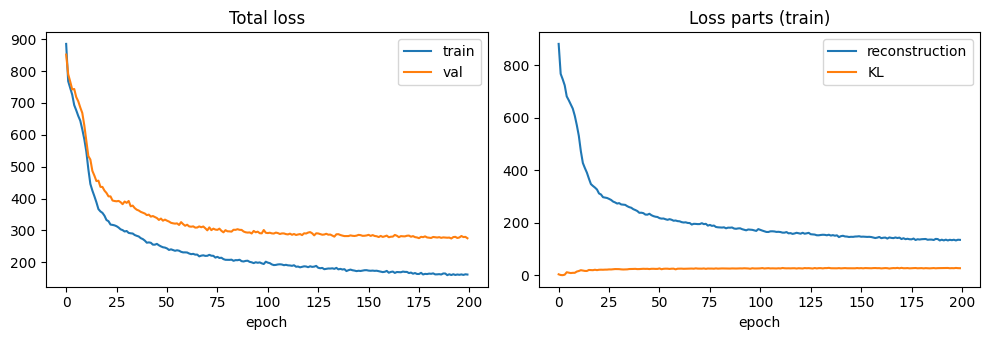

In [7]:
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="val")
plt.title("Total loss"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["recon_loss"], label="reconstruction"); plt.plot(history.history["kl_loss"], label="KL")
plt.title("Loss parts (train)"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout(); plt.show()

## 5. Reconstructions (original on top, reconstructed below)

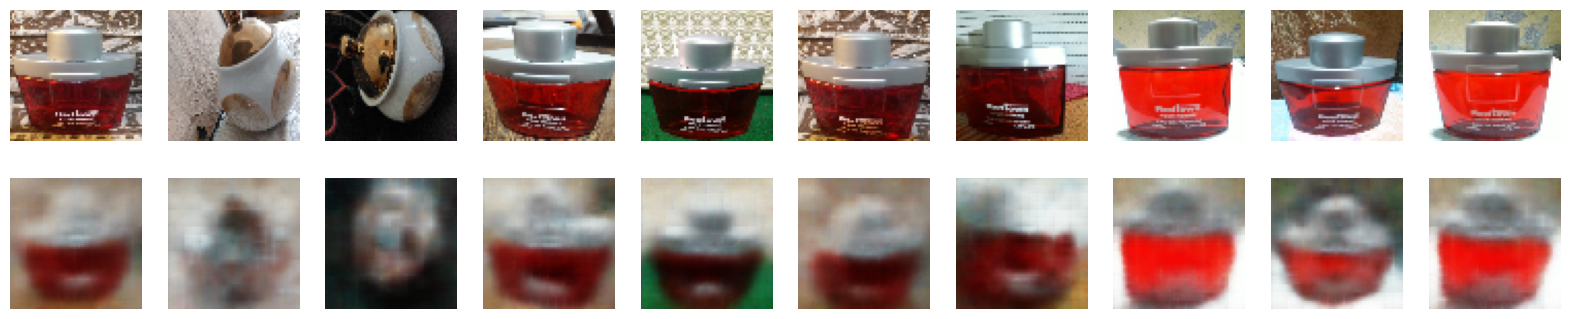

In [8]:
x = next(iter(val_ds))
recon = vae(x).numpy()
n = min(10, len(x))
plt.figure(figsize=(2 * n, 4))
for i in range(n):
    plt.subplot(2, n, i + 1);     plt.imshow(x[i]);     plt.axis("off")
    plt.subplot(2, n, n + i + 1); plt.imshow(recon[i]); plt.axis("off")
plt.show()

## 6. Generate new images

New images come from sampling `z ~ N(0, 1)` and passing it through the decoder.

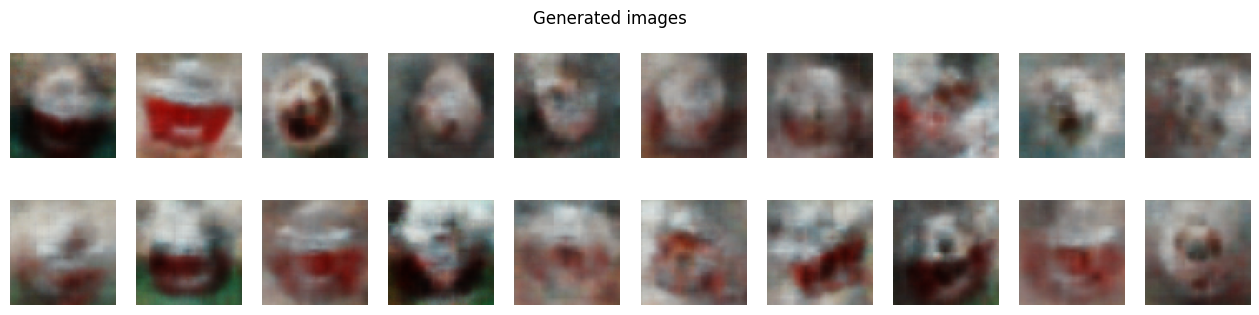

In [9]:
z_samples = np.random.normal(size=(20, LATENT_DIM)).astype("float32")
generated = decoder.predict(z_samples, verbose=0)

plt.figure(figsize=(16, 3.5))
for i in range(20):
    plt.subplot(2, 10, i + 1)
    plt.imshow(generated[i]); plt.axis("off")
plt.suptitle("Generated images"); plt.show()

## 7. Save the models

In [ ]:
os.makedirs("saved_models", exist_ok=True)
encoder.save("saved_models/encoder.keras")
decoder.save("saved_models/decoder.keras")

## Notes
- With only about 200 images the output will be blurry. That is normal for a VAE on a small dataset.
- Try `BETA` below 1 for sharper reconstructions, and a bigger `LATENT_DIM` if the images are complex.